# TG4DAC × WarpSpeed — experiment record

**Board:** NVIDIA RTX PRO 6000 Blackwell Server Edition · SM120 · 188 SMs · measured 1,529 GB/s DRAM, 128 MiB L2, 437 TFLOPS `mma.sync` BF16 (FP32 acc). One owned Colab G4 allocation. **Model:** Gemma 4 31B (`google/gemma-4-31B-it-qat-w4a16-ct@52f3f65b`).

**Pipeline:** planner `cake_scoped_c1` (31B LoRA) → refiner → Claude (implementer). **Altair:** dense MLP, seeded with the user's kernels; refiner = vega 12B e3. **Deneb:** attention, seeded with vLLM 0.32 `TRITON_ATTN`; refiner = new 31B WarpSpeed refiner (CAKE SFT). Every number below is read from the run records (`../altair/results.csv`, `results.csv`, `corpus.jsonl.gz`) or executed in this notebook.

In [1]:
import ast, csv, gzip, json, math, sys, collections
from pathlib import Path
import pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.path import Path as MPath
from matplotlib.patches import PathPatch
from IPython.display import display, Markdown

csv.field_size_limit(2**31 - 1)
DENEB = Path.cwd(); ALTAIR = DENEB.parent / "altair"
sys.path.insert(0, str(DENEB)); import warpspeed_tool as W

def records(path, kind):
    path = Path(path)
    if not path.is_file(): return []
    return [dict(r, p=json.loads(r["payload_json"])) for r in csv.DictReader(path.open()) if r["record_type"] == kind]

SURFACE, INK, INK2, GRID, AXIS, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#ecebe7", "#d9d8d4", "#c3c2b7"
S1, S2, S3 = "#2a78d6", "#eb6834", "#1baf7a"           # validated categorical slots 1-3 (all-pairs, light)
mpl.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 9.5, "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": AXIS,
    "axes.linewidth": 1, "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 10, "legend.frameon": False, "legend.fontsize": 9})
pd.set_option("display.max_colwidth", 120)

def hbars(ax, cats, series, thick=14, gap=2, group_gap=16, label_fmt="{:.2f}", ref=None, xmax=None, xlabel="", legend=True):
    # Horizontal bars <=24 px, 4 px rounded data-end (square at the baseline), 2 px surface gap inside a group.
    n = len(series); band = n * thick + (n - 1) * gap + group_gap
    H = band * len(cats)
    xmax = xmax or 1.18 * max(max(v for v in s[1] if v is not None) for s in series)
    ax.set_xlim(0, xmax); ax.set_ylim(H, 0)
    ax.figure.canvas.draw()
    T = ax.transData
    for gi, c in enumerate(cats):
        for si, (name, vals, color) in enumerate(series):
            v = vals[gi]
            if v is None: continue
            y0 = gi * band + group_gap / 2 + si * (thick + gap)
            (X0, Ya), (X1, Yb) = T.transform((0, y0)), T.transform((v, y0 + thick))
            lo, hi = min(Ya, Yb), max(Ya, Yb)
            r = min(4, (X1 - X0) / 2, (hi - lo) / 2)
            verts = [(X0, lo), (X1 - r, lo), (X1, lo), (X1, lo + r), (X1, hi - r), (X1, hi), (X1 - r, hi), (X0, hi), (X0, lo)]
            codes = [MPath.MOVETO, MPath.LINETO, MPath.CURVE3, MPath.CURVE3, MPath.LINETO, MPath.CURVE3, MPath.CURVE3,
                     MPath.LINETO, MPath.CLOSEPOLY]
            ax.add_patch(PathPatch(MPath(T.inverted().transform(verts), codes), facecolor=color, edgecolor="none"))
            if label_fmt: ax.text(v + xmax * 0.008, y0 + thick / 2, label_fmt.format(v), va="center", ha="left", fontsize=8.5, color=INK2)
    ax.set_yticks([gi * band + band / 2 for gi in range(len(cats))], cats)
    ax.grid(axis="x", color=GRID, linewidth=1); ax.set_axisbelow(True); ax.spines["left"].set_visible(False)
    ax.set_xlabel(xlabel)
    if ref is not None:
        ax.axvline(ref[0], color=INK2, linewidth=1)
        if n == 1: ax.text(ref[0], -band * 0.05, " " + ref[1], color=INK2, fontsize=8.5, va="bottom", ha="left")
    if n > 1 and legend:
        handles = [mpl.patches.Patch(color=c, label=nm) for nm, _, c in series]
        if ref is not None: handles.append(mpl.lines.Line2D([], [], color=INK2, linewidth=1, label=ref[1]))
        ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=min(3, len(handles)),
                  borderaxespad=0.2, handlelength=1.2, columnspacing=1.6)

def fig_rows(n_groups, n_series, panels=1, width=9.2):
    band_px = n_series * 14 + (n_series - 1) * 2 + 16
    h = (band_px * n_groups) / 110 + 0.9
    return plt.subplots(1, panels, figsize=(width, h), squeeze=False)[1][0]

def pending(what): display(Markdown(f"*Pending:* {what}"))

## 1 · Altair — dense MLP, W4A16 + rank-16 LoRA (H 5376, I 21504), seeded with the user's kernels

**1.1 Seed vs final, complete forward.** CUDA-graph median ms; `forge_*` are the user's kernels after Altair's added variants were tuned in; `dec_cublas` = decode-to-BF16 + cuBLAS reference.

In [2]:
meas = records(ALTAIR / "results.csv", "measurement")
def run(tag, M, design): return next((m["p"] for m in meas if m["config_id"] == tag and m["p"]["M"] == M and m["p"]["design"] == design and "forward_ms" in m["p"]), None)
rows = []
for M, d in ((8, "forge_gemv8"), (7131, "forge_tc"), (15329, "forge_tc")):
    b, f = run("altair_baseline", M, d), run("altair_bench_wsdm" if M > 8 else "altair_bench", M, d)
    ref = run("altair_bench", M, "dec_cublas")
    rows.append({"M": M, "seed design": d, "seed ms": b["forward_ms"], "final ms": f["forward_ms"], "final / seed": f["forward_ms"] / b["forward_ms"],
                 "final config": " · ".join(map(str, f["config"])), "dec_cublas ms": ref["forward_ms"] if ref else None,
                 "TFLOPS": f["TFLOPS"], "% SOL": f["sol_pct"], "rel L2 %": f["numerical"]["relative_l2_pct"]})
display(pd.DataFrame(rows).style.format({"seed ms": "{:.4f}", "final ms": "{:.4f}", "final / seed": "{:.3f}", "dec_cublas ms": "{:.4f}",
                                         "TFLOPS": "{:.1f}", "% SOL": "{:.1f}", "rel L2 %": "{:.4f}"}, na_rep="—").hide(axis="index"))

M,seed design,seed ms,final ms,final / seed,final config,dec_cublas ms,TFLOPS,% SOL,rel L2 %
8,forge_gemv8,0.0993,0.0963,0.970,hint95 · fg_gu8h · fg_dn8h,—,57.6,43.2,0.0627
7131,forge_tc,14.1598,14.1483,0.999,fg_gu_d · ws_dn_ws+sk,14.1109,349.6,79.8,0.0117
15329,forge_tc,30.2863,30.3223,1.001,ws_gu_ws · ws_dn_ws+sk · no-pdl,29.9541,350.7,80.0,0.0124


**1.2 Model episodes.** Planner = `cake_scoped_c1`, CAKE tool-first protocol (6 calls / 12,288 tokens; attempt 0 T=0, 1–3 T=0.6). Refiner = vega 12B e3 (`selected_12b_pair` profile).

In [3]:
def episodes(path, kind, short=110):
    out = []
    for e in records(path, kind):
        p = e["p"]
        if "tool_executions" in p:
            calls = p.get("tool_executions", []); ok = sum(1 for t in calls if (t.get("actual_result") or {}).get("ok"))
            text = (p.get("final_content") or "").replace("\n", " ")
            out.append({"problem": p.get("problem_id"), "finished": p.get("finished"), "stop": p.get("stop_reason"),
                        "calls": len(calls), "calls ok": ok, "completion tok": p.get("used_completion_tokens"), "final (head)": text[:short]})
        else:
            r = p.get("response"); r = ast.literal_eval(r) if isinstance(r, str) and r.startswith("{") else (r or {})
            calls = r.get("tool_executions", []) or []; ok = sum(1 for t in calls if (t.get("actual_result") or {}).get("ok"))
            out.append({"problem": p.get("problem_id"), "finished": r.get("finished"), "stop": r.get("stop_reason"), "calls": len(calls),
                        "calls ok": ok, "completion tok": r.get("completion_tokens"), "final (head)": (r.get("proposal") or "").replace("\n", " ")[:short]})
    return pd.DataFrame(out)
pl, rf = episodes(ALTAIR / "results.csv", "planner_episode"), episodes(ALTAIR / "results.csv", "refiner_episode")
display(Markdown(f"Planner: **{int(pl.finished.sum())}/{len(pl)}** finished · tool calls ok **{pl['calls ok'].sum()}/{pl['calls'].sum()}**. "
                 f"Refiner: **{int(rf.finished.fillna(False).sum())}/{len(rf)}** finished · stops {dict(collections.Counter(rf.stop))}."))
display(pl.style.hide(axis="index")); display(rf.style.hide(axis="index"))

Planner: **12/12** finished · tool calls ok **31/49**. Refiner: **5/12** finished · stops {'stop': 5, 'length': 5, 'native_context_budget_exhausted': 2}.

problem,finished,stop,calls,calls ok,completion tok,final (head)
altair_dense_M8_p0,True,stop,3,1,2959,The current `gemv8` design for the `fg_gu8h` and `fg_dn8h` kernels uses a register prefetch depth of `DG=3`. G
altair_dense_M7131_p0,True,stop,6,4,3110,"```json { ""proposal"": { ""proposal_path"": ""ws_gemm_BK32_ST4"", ""changes"": { ""BK"": 32, ""ST"""
altair_dense_M15329_p0,True,stop,5,4,3021,"```json { ""proposal"": { ""proposal_path"": ""ws_gu_w_st3"", ""changes"": { ""BK"": 64, ""ST"": 3,"
altair_dense_M8_p1,True,stop,5,1,3205,"The current `gemv8` kernel uses a register prefetch depth $DG=3$, which consumes approximately $16 + 3 \times"
altair_dense_M7131_p1,True,stop,5,3,3402,"The current design for the `Down` GEMM uses a warp-specialized (`ws_dn_ws+sk`) configuration with `BM=128, BN="
altair_dense_M15329_p1,True,stop,6,4,3517,The current design employs a warp-specialized MMA squad configuration with a register-heavy accumulator set (1
altair_dense_M8_p2,True,stop,3,2,3151,"The current `gemv8` implementation uses a register prefetch depth of `DG=3`, which is relatively shallow for a"
altair_dense_M7131_p2,True,stop,2,2,3253,"The current `ws_dn_ws` configuration uses a `BM=128, BN=128, BK=64` tile with a register usage of 168 and shar"
altair_dense_M15329_p2,True,stop,5,4,3116,"```json { ""proposal"": { ""changed_maps"": { ""squad_roles"": ""Unchanged: warps 0-3, 4-7 as MMA squads;"
altair_dense_M8_p3,True,stop,3,1,3068,The current `gemv8` design uses a register prefetch depth of `DG=3` to hide memory latency during the operand-


problem,finished,stop,calls,calls ok,completion tok,final (head)
altair_dense_M8_p0,True,stop,5,1,6657,The current design for the `gemv8` kernel (used in `fg_gu8` and `fg_dn8`) utilizes a register prefetch depth o
altair_dense_M7131_p0,False,length,0,0,8192,"```json { ""proposal"": { ""proposal_path"": ""ws_gemm_BK32_ST4"", ""changes"": { ""BK"": 32, ""ST"""
altair_dense_M15329_p0,False,native_context_budget_exhausted,3,1,14534,
altair_dense_M8_p1,False,length,0,0,8192,"```python import numpy as np from pycute import Layout, Tensor, Accessor, basis, F2 # Contract and Architectu"
altair_dense_M7131_p1,False,length,4,1,13817,
altair_dense_M15329_p1,False,length,4,3,11015,The `shared_A_map` for `TK=64` is verified to be a valid permutation of `0..63`. Now I need to verify the `ow
altair_dense_M8_p2,True,stop,0,0,5352,"```json { ""proposal"": { ""changes"": [ { ""path"": ""gemv8"", ""role"": ""prefetch_depth"","
altair_dense_M7131_p2,False,length,0,0,8192,"To refine the SM120 W4A16 dense MLP forward with rank16 LoRA, I will first execute the layout calculation for"
altair_dense_M15329_p2,True,stop,10,1,12738,The current design for the SM120 W4A16 dense MLP forward with rank16 LoRA is being refined to optimize the fus
altair_dense_M8_p3,True,stop,9,2,15178,The current design for the SM120 W4A16 MLP is constrained by the register requirements of the `gemv8` kernel.


**1.3 Implemented designs → per-stage time.** Best seed kernel per stage vs Claude's dequant-ahead implementation of the planner's M7131 p2 idea (`wsd`: 3-phase ring L→D→C, bitwise-exact) and its coupled WM=64 follow-up. CUDA-graph per-stage ms.

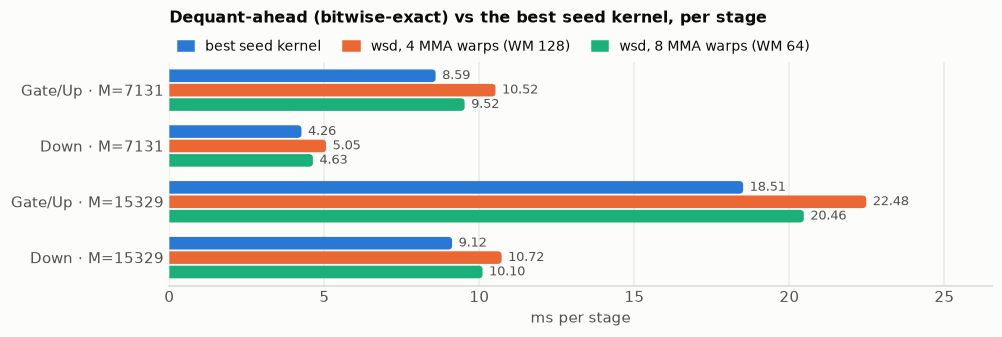

stage,best seed kernel,seed ms,wsd WM128 ms,wsd WM64 ms,WM64 / seed
Gate/Up · M=7131,fg_gu_d,8.587,10.519,9.524,1.109
Down · M=7131,ws_dn_ws+sk,4.261,5.053,4.629,1.087
Gate/Up · M=15329,ws_gu_ws,18.507,22.477,20.462,1.106
Down · M=15329,fg_dn_d,9.117,10.716,10.102,1.108


**M=8 prefetch depth (planner DG 3→6/7 ×4, refiner M8 p3):** CUDA-graph ms per forward, all replay-exact.

ms,L2 mode,Gate/Up kernel,Down kernel,replay exact
0.0992,hint95,fg_gu8h,fg_dn8h,True
0.1051,hint95,fg_gu8h_d7a,fg_dn8h,True
0.1177,hint95,fg_gu8h,fg_dn8h_d6,True
0.1254,hint95,fg_gu8h_d7a,fg_dn8h_d6,True
0.1311,hint95,fg_gu8h,fg_dn8h_d7,True
0.1409,hint95,fg_gu8h_d7b,fg_dn8h,True
0.1410,hint0,fg_gu8h,fg_dn8h,True
0.1414,hint95,fg_gu8h_d7a,fg_dn8h_d7,True
0.1475,hint0,fg_gu8h_d7a,fg_dn8h,True
0.1496,hint0,fg_gu8h,fg_dn8h_d6,True


In [4]:
tune = {m["p"]["M"]: m["p"]["tune"] for m in meas if m["config_id"] == "altair_bench_wsdm" and m["p"]["design"] == "forge_tc"}
cats, inc, w128, w64, lab = [], [], [], [], []
for M in (7131, 15329):
    for st, nm in (("gu", "Gate/Up"), ("dn", "Down")):
        t = tune[M][st]
        seed = min((v, k) for k, v in t.items() if not k.startswith("wsd"))
        best = lambda pre: min(v for k, v in t.items() if k.split("+")[0] in pre)
        cats.append(f"{nm} · M={M}"); inc.append(seed[0]); lab.append(seed[1])
        w128.append(best({f"wsd_{st}_a", f"wsd_{st}_s", f"wsd_{st}_c"})); w64.append(best({f"wsd_{st}_m", f"wsd_{st}_ms"}))
ax, = fig_rows(len(cats), 3)
hbars(ax, cats, [("best seed kernel", inc, S1), ("wsd, 4 MMA warps (WM 128)", w128, S2), ("wsd, 8 MMA warps (WM 64)", w64, S3)], xlabel="ms per stage")
ax.set_title("Dequant-ahead (bitwise-exact) vs the best seed kernel, per stage", pad=26)
plt.tight_layout(); plt.show()
display(pd.DataFrame({"stage": cats, "best seed kernel": lab, "seed ms": inc, "wsd WM128 ms": w128, "wsd WM64 ms": w64,
                      "WM64 / seed": [b / a for a, b in zip(inc, w64)]}).style.format(precision=3).hide(axis="index"))
v8 = run("altair_bench", 8, "forge_gemv8")["gemv8_variants"]
display(Markdown("**M=8 prefetch depth (planner DG 3→6/7 ×4, refiner M8 p3):** CUDA-graph ms per forward, all replay-exact."))
display(pd.DataFrame(v8, columns=["ms", "L2 mode", "Gate/Up kernel", "Down kernel", "replay exact"]).sort_values("ms").style.format({"ms": "{:.4f}"}).hide(axis="index"))

**1.4 SM120 register cap = 65536 / (128 · ⌈warps/4⌉), floored to 8, ≤ 255** (no `setmaxnreg`). Compiled registers of every warp-specialized kernel in the final bench vs the rule.

In [5]:
env = next(m["p"] for m in records(ALTAIR / "results.csv", "bench_environment") if m["config_id"] == "altair_bench_wsdm")
def warps(n):
    if n.startswith("ws_"): return 9
    s = n.split("_")[-1]
    return {"a": 7, "c": 7, "s": 7, "b": 9, "m": 11, "ms": 11, "m4": 13}[s]
rows = [{"kernel": n, "warps": warps(n), "rule cap": W.launch_register_cap(warps(n)), "compiled regs": k["regs"], "local B": k["local"],
         "spill": k["local"] > 8} for n, k in sorted(env["kernels"].items()) if n.startswith(("ws_", "wsd_"))]
df = pd.DataFrame(rows)
display(Markdown(f"compiled regs ≤ rule cap for **{int((df['compiled regs'] <= df['rule cap']).sum())}/{len(df)}** kernels; "
                 + "; ".join(f"{w} warps: {g['compiled regs'].min()}–{g['compiled regs'].max()} regs (cap {W.launch_register_cap(w)})" for w, g in df.groupby('warps'))))
display(df.style.hide(axis="index"))

compiled regs ≤ rule cap for **34/34** kernels; 7 warps: 255–255 regs (cap 255); 9 warps: 160–168 regs (cap 168); 11 warps: 166–166 regs (cap 168); 13 warps: 128–128 regs (cap 128)

kernel,warps,rule cap,compiled regs,local B,spill
ws_dn_a,9,168,168,352,True
ws_dn_b,9,168,168,368,True
ws_dn_h,9,168,162,8,False
ws_dn_hb,9,168,166,8,False
ws_dn_hs,9,168,162,8,False
ws_dn_hw,9,168,168,8,False
ws_dn_s,9,168,168,352,True
ws_dn_w,9,168,168,312,True
ws_dn_wb,9,168,168,320,True
ws_dn_ws,9,168,168,312,True


**1.5 End-to-end decode, vLLM 0.32.0, Gemma 4 31B + `cake_scoped_c1`.** 556-token prompt, 256 greedy steps, step = (t₂₅₇ − t₁)/256, best of 3. `gemv8` = the user's M=8 MLP chain in every layer (L2 mode `none`); `stock` = Marlin + Punica LoRA; both eager + full decode CUDA graphs; `stock_compiled` = vLLM default `torch.compile`.

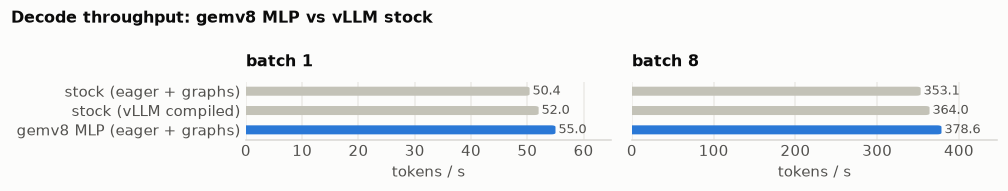

batch,stock ms,stock_compiled ms,gemv8 ms,× vs stock,× vs compiled,greedy tokens identical before divergence
1,19.84,19.23,18.18,1.091,1.058,[28]
8,22.66,21.98,21.13,1.072,1.040,"[28, 102, 257, 208, 45, 232, 128, 257]"


In [6]:
dec = {(d["p"]["mode"], d["p"]["batch"]): d["p"] for d in records(ALTAIR / "results.csv", "decode_measurement")}
modes = [("stock", "stock (eager + graphs)"), ("stock_compiled", "stock (vLLM compiled)"), ("gemv8", "gemv8 MLP (eager + graphs)")]
axs = fig_rows(3, 1, panels=2)
for ax, B in zip(axs, (1, 8)):
    vals = [dec[(m, B)]["decode_tokens_per_s"] for m, _ in modes]
    hbars(ax, [n for _, n in modes], [("tok/s", vals, S1)], label_fmt="{:.1f}", xlabel="tokens / s")
    for patch, (m, _) in zip(ax.patches, modes):
        if m != "gemv8": patch.set_facecolor(MUTED)
    ax.set_title(f"batch {B}")
    if B == 8: ax.set_yticklabels([])
plt.suptitle("Decode throughput: gemv8 MLP vs vLLM stock", x=0.01, ha="left", fontsize=10.5, fontweight="bold")
plt.tight_layout(); plt.show()
rows = []
for B in (1, 8):
    s, c, g = (dec[(m, B)] for m in ("stock", "stock_compiled", "gemv8"))
    agree = [next((i for i, (x, y) in enumerate(zip(a, b)) if x != y), len(a)) for a, b in zip(g["tokens"], s["tokens"])]
    rows.append({"batch": B, "stock ms": s["decode_step_ms"], "stock_compiled ms": c["decode_step_ms"], "gemv8 ms": g["decode_step_ms"],
                 "× vs stock": s["decode_step_ms"] / g["decode_step_ms"], "× vs compiled": c["decode_step_ms"] / g["decode_step_ms"],
                 "greedy tokens identical before divergence": agree})
display(pd.DataFrame(rows).style.format({"stock ms": "{:.2f}", "stock_compiled ms": "{:.2f}", "gemv8 ms": "{:.2f}", "× vs stock": "{:.3f}", "× vs compiled": "{:.3f}"}).hide(axis="index"))

## 2 · Deneb — Gemma 4 31B attention, seeded with vLLM 0.32 `TRITON_ATTN`

**Contract `gemma4-31b-attn-v1`, one layer.** o[t,h] = softmax_j(q[t,h]·K[j,g(h)]) V[j,g(h)], scale 1.0, FP32 scores/softmax, BF16 P for P·V, FP32 acc, BF16 out; inputs as vLLM passes them (q after norm+RoPE; paged cache `[blocks, Hkv, page, 2d]`). **M** = query tokens per call (decode: one per sequence; prefill/training: one causal sequence, the MLP's M). **L** = cached positions each query reads.

| layer | count | Hq/Hkv | d | reads | page | decode shapes | prefill shapes |
|---|---|---|---|---|---|---|---|
| sliding | 50 | 32/16 | 256 | last 1,024 | 16 | M ∈ {1, 8} × L ∈ {4k, 32k, 128k} | M ∈ {7131, 15329}, L = M |
| global | 10 | 32/4 | 512 | all (causal); V = k/rms(k), K = RoPE(w_k ⊙ V) | 32 | same | same |

**2.1 Seed vs SOL, decode.** SOL = (KV + q/o bytes) / 1,529 GB/s. Per-layer CUDA-graph median; each measurement rotates n independent caches (≥ 4× L2), as consecutive layers do. Every case runs vLLM's 3D split-softmax path.

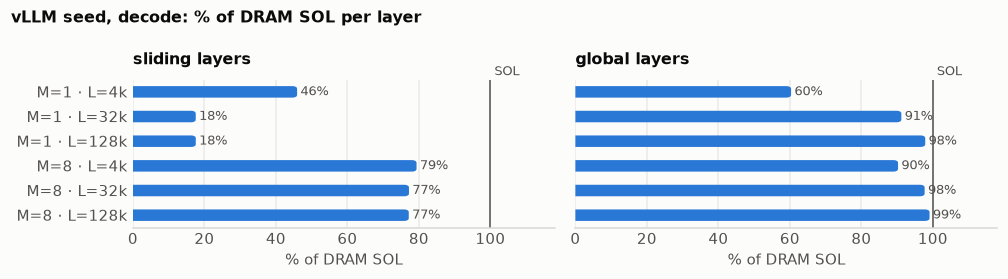

layer,M,L,seed µs,SOL µs,% SOL,segments,caches rotated,rel L2
sliding,1,4096,23.9,11.0,45.9,16,16,1.53e-03
sliding,1,32768,62.6,11.0,17.6,16,16,1.54e-03
sliding,1,131072,62.5,11.0,17.6,16,16,1.54e-03
sliding,8,4096,110.8,88.0,79.4,16,4,1.45e-03
sliding,8,32768,113.9,88.0,77.2,16,4,1.46e-03
sliding,8,131072,114.0,88.0,77.2,16,4,1.46e-03
global,1,4096,36.4,22.0,60.3,64,16,1.34e-03
global,1,32768,192.6,175.6,91.2,64,2,1.48e-03
global,1,131072,717.6,702.3,97.9,64,1,1.38e-03
global,8,4096,194.9,175.9,90.3,16,2,1.39e-03


In [7]:
att = records(DENEB / "results.csv", "attention_measurement")
dec_rows = [a["p"] for a in att if a["p"].get("phase", "decode") == "decode"]
pf_rows = [a["p"] for a in att if a["p"].get("phase") == "prefill"]
axs = fig_rows(6, 1, panels=2)
for ax, kind in zip(axs, ("sliding", "global")):
    rs = [r for r in dec_rows if r["kind"] == kind]
    hbars(ax, [f"M={r['B']} · L={r['L'] // 1024}k" for r in rs], [("% of SOL", [r["incumbent"]["pct_of_sol"] for r in rs], S1)],
          label_fmt="{:.0f}%", xmax=118, ref=(100, "SOL"), xlabel="% of DRAM SOL")
    ax.set_title(f"{kind} layers")
    if kind == "global": ax.set_yticklabels([])
plt.suptitle("vLLM seed, decode: % of DRAM SOL per layer", x=0.01, ha="left", fontsize=10.5, fontweight="bold")
plt.tight_layout(); plt.show()
display(pd.DataFrame([{"layer": r["kind"], "M": r["B"], "L": r["L"], "seed µs": 1e3 * r["incumbent"]["median_ms"], "SOL µs": 1e3 * r["sol_ms"],
                       "% SOL": r["incumbent"]["pct_of_sol"], "segments": r["incumbent"]["segments"], "caches rotated": r["rotated_caches"],
                       "rel L2": r["incumbent"]["rel_l2"]} for r in dec_rows]).style.format(
    {"seed µs": "{:.1f}", "SOL µs": "{:.1f}", "% SOL": "{:.1f}", "rel L2": "{:.2e}"}).hide(axis="index"))

**2.2 Seed vs peak, prefill/training.** SOL = 4 · Σᵢ min(i+1, window) · Hq · d FLOP at 437 TFLOPS. CUDA-graph median; numerics on 256 strided query rows vs FP32.

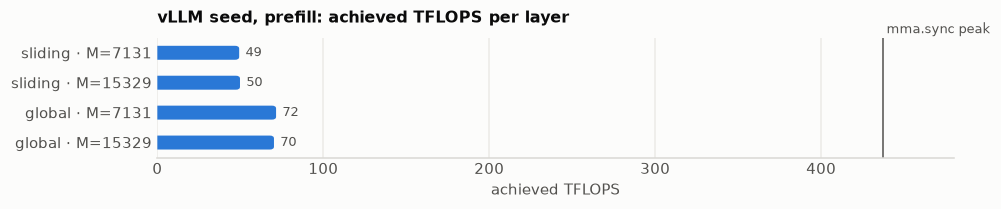

layer,M,seed ms,SOL ms,% peak,TFLOPS,rel L2
sliding,7131,4.505,0.508,11.3,49.3,1.46e-03
sliding,15329,9.984,1.138,11.4,49.8,1.46e-03
global,7131,23.293,3.814,16.4,71.5,1.35e-03
global,15329,109.576,17.621,16.1,70.3,1.37e-03


In [8]:
ax, = fig_rows(4, 1)
hbars(ax, [f"{r['kind']} · M={r['M']}" for r in pf_rows], [("TFLOPS", [r["incumbent"]["tflops"] for r in pf_rows], S1)],
      label_fmt="{:.0f}", xmax=480, ref=(437, "mma.sync peak"), xlabel="achieved TFLOPS")
ax.set_title("vLLM seed, prefill: achieved TFLOPS per layer"); plt.tight_layout(); plt.show()
display(pd.DataFrame([{"layer": r["kind"], "M": r["M"], "seed ms": r["incumbent"]["median_ms"], "SOL ms": r["sol_ms"], "% peak": r["incumbent"]["pct_of_sol"],
                       "TFLOPS": r["incumbent"]["tflops"], "rel L2": r["incumbent"]["rel_l2"]} for r in pf_rows]).style.format(
    {"seed ms": "{:.3f}", "SOL ms": "{:.3f}", "% peak": "{:.1f}", "TFLOPS": "{:.1f}", "rel L2": "{:.2e}"}).hide(axis="index"))

**2.3 Seed as compiled** (Triton 3.7.1, every kernel built for these shapes).

In [9]:
compiled = [k for c in records(DENEB / "results.csv", "compiled_kernels") for k in c["p"]["kernels"]]
display(pd.DataFrame([{"kernel": c["kernel"], "path": "3D" if c["constants"].get("IS_3D") else ("—" if c["kernel"] == "reduce_segments" else "2D"),
                       "d": c["constants"].get("HEAD_SIZE"), "TILE": c["constants"].get("TILE_SIZE"), "BLOCK_M": c["constants"].get("BLOCK_M"),
                       "segments": c["constants"].get("NUM_SEGMENTS_PER_SEQ"), "warps": c["num_warps"], "stages": c["num_stages"],
                       "regs": c["n_regs"], "spills": c["n_spills"], "smem B": c["shared"]} for c in compiled]).drop_duplicates().style.hide(axis="index"))

kernel,path,d,TILE,BLOCK_M,segments,warps,stages,regs,spills,smem B
kernel_unified_attention,3D,256,32,16.000000,16,4,3,160,0,58624
kernel_unified_attention,3D,512,16,16.000000,64,4,3,184,0,49792
kernel_unified_attention,3D,512,16,16.000000,16,4,3,184,0,49792
reduce_segments,—,256,32,nan,16,4,3,40,0,2048
reduce_segments,—,512,16,nan,64,4,3,87,0,8
reduce_segments,—,512,16,nan,16,4,3,40,0,0
kernel_unified_attention,2D,256,32,16.000000,1,4,3,188,0,58624
kernel_unified_attention,2D,512,32,16.000000,1,4,3,255,34,83200


**2.4 `warpspeed_check` (typed CPU tool, CCCL `036ecd2d` semantics) reproduces the measured SM120 facts.** Executed here.

In [10]:
def ring(name, st, stride, phases, align=1024): return dict(name=name, stages=st, stride_bytes=stride, align=align, phases=phases)
ab = lambda own: [ring("ab0", 2, 21504, [dict(owners=[own], tx_bytes=20992), dict(owners=["mma0"])]), ring("ab1", 2, 21504, [dict(owners=[own], tx_bytes=20992), dict(owners=["mma1"])])]
wsd = lambda mma, dq, need: dict(squads=[dict(name="mma", warps=mma, regs_needed=need), dict(name="dequant", warps=dq), dict(name="producer", warps=1)],
                                resources=[ring("stage", 2, 37888, [dict(owners=["producer"], tx_bytes=20992), dict(owners=["dequant"]), dict(owners=["mma"])])])
plans = [
  ("user v3, 2×4 MMA + 1 producer (288 T)", dict(squads=[dict(name="mma0", warps=4, regs_needed=200), dict(name="mma1", warps=4, regs_needed=200), dict(name="producer", warps=1)], resources=ab("producer")), "168 regs, 312–376 B spill"),
  ("same, setmaxnreg 232/232/40", dict(squads=[dict(name="mma0", warps=4, regs=232), dict(name="mma1", warps=4, regs=232), dict(name="producer", warps=1, regs=40)], resources=ab("producer")), "40/232 split fell back to 168"),
  ("producer widened to a warpgroup, 232/40 (384 T)", dict(squads=[dict(name="mma0", warps=4, regs=232, regs_needed=200), dict(name="mma1", warps=4, regs=232, regs_needed=200), dict(name="producer", warps=4, regs=40)], resources=ab("producer")), "(CAKE WS384 realized R221)"),
  ("wsd 4 MMA + 2 dequant + 1 (224 T)", wsd(4, 2, 200), "255 regs"),
  ("wsd 4 MMA + 4 dequant + 1 (288 T)", wsd(4, 4, 200), "168 regs, 320–392 B spill"),
  ("wsd 8 MMA + 2 dequant + 1 (352 T)", wsd(8, 2, 110), "166 regs, no spill"),
  ("wsd 8 MMA + 4 dequant + 1 (416 T)", wsd(8, 4, 110), "128 regs, 72–88 B spill"),
  ("CAKE WS640: 16 consumer + 4 producer, 104/56", dict(squads=[dict(name="consumer", warps=16, regs=104), dict(name="producer", warps=4, regs=56)], resources=[]), "initial 96, R101"),
]
rows = []
for name, plan, compiled in plans:
    r = W.execute("warpspeed_check", plan)["result"]
    rows.append({"plan": name, "pass": r["pass"], "launch cap": r["registers"]["launch_cap"], "pool": r["registers"]["launch_pool"],
                 "requested": r["registers"]["requested_total"], "first MMA squad / sub-partition": r["squads"][0]["warps_per_subpartition"],
                 "violations": ", ".join(v["code"] for v in r["violations"]) or "—", "compiled on G4": compiled})
display(pd.DataFrame(rows).style.hide(axis="index"))

plan,pass,launch cap,pool,requested,first MMA squad / sub-partition,violations,compiled on G4
"user v3, 2×4 MMA + 1 producer (288 T)",False,168,48384,48384,"[1, 1, 1, 1]","register_fit, register_fit","168 regs, 312–376 B spill"
"same, setmaxnreg 232/232/40",False,168,48384,60672,"[1, 1, 1, 1]","setmaxnreg_alignment, setmaxnreg_pool",40/232 split fell back to 168
"producer widened to a warpgroup, 232/40 (384 T)",True,168,64512,64512,"[1, 1, 1, 1]",—,(CAKE WS384 realized R221)
wsd 4 MMA + 2 dequant + 1 (224 T),True,255,57120,57120,"[1, 1, 1, 1]",—,255 regs
wsd 4 MMA + 4 dequant + 1 (288 T),False,168,48384,48384,"[1, 1, 1, 1]",register_fit,"168 regs, 320–392 B spill"
wsd 8 MMA + 2 dequant + 1 (352 T),True,168,59136,59136,"[2, 2, 2, 2]",—,"166 regs, no spill"
wsd 8 MMA + 4 dequant + 1 (416 T),True,128,53248,53248,"[2, 2, 2, 2]",—,"128 regs, 72–88 B spill"
"CAKE WS640: 16 consumer + 4 producer, 104/56",True,96,61440,60416,"[4, 4, 4, 4]",—,"initial 96, R101"


**2.5 Refiner curriculum** (`corpus.py`): every tool result executed on CPU; final plans bound to results by JSON pointer; attention excluded (held-out target).

In [11]:
rows = [json.loads(l) for l in gzip.open(DENEB / "corpus.jsonl.gz", "rt")]
man, ex = rows[0], rows[1:]
agg = collections.defaultdict(lambda: collections.Counter())
for e in ex:
    a = agg[(e["family"], e["split"])]
    a["examples"] += 1; a["tool calls"] += len(e["trajectory"]["calls"])
    a["warpspeed_check"] += sum(c["function"] == "warpspeed_check" for c in e["trajectory"]["calls"])
    a["counterexamples bound"] += sum(b.get("kind") == "counterexample" for b in e["target"]["bindings"])
    a["synthetic"] += e["trajectory"]["synthetic_exercise"]
df = pd.DataFrame([{"family": f, "split": s, **c} for (f, s), c in sorted(agg.items())]).fillna(0)
display(Markdown(f"**{man['examples']}** examples ({man['train']} train) · **{man['calls']}** executed calls · tools: {man['tools']}"))
display(df.style.hide(axis="index"))

**30** examples (29 train) · **64** executed calls · tools: v3 PyCuTe (cac71fe7) + warpspeed_check (CCCL 036ecd2d semantics)

family,split,examples,tool calls,warpspeed_check,counterexamples bound,synthetic
altair_dequant_ahead,train,4,8,8,1,0
cake_fi_ws,eval,1,1,1,0,0
cake_fi_ws,train,1,1,1,0,0
cccl_lookahead_scan,train,7,11,11,7,1
drills,train,7,13,13,6,6
forge_gemv8,train,3,10,6,2,0
forge_ws_gemm_v3,train,7,20,12,6,0


**2.6 Refiner SFT** (CAKE procedure: parent `cake_scoped_c1` FP32 factors, fresh AdamW, lr 2e-5 cosine, 2 epochs, ≤ 8 examples / update, 8,192-token whole examples, tool outputs masked).

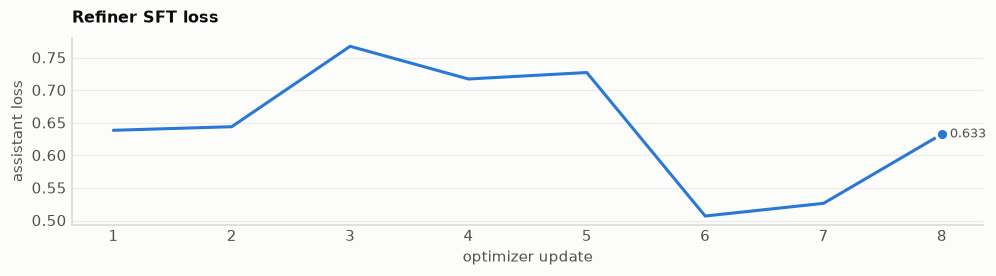

updates,example visits,processed tokens,supervised tokens,update seconds,held-out before,held-out after
8,58,353594,92236,435.723749,"{'examples': 1, 'rows': [{'id': 'cake_ws640__consumer_split', 'loss': 1.0677733421325684, 'targets': 637, 'tokens': 4143}], 'token_weighted_loss': 1.0677733421325684, 'optimizer_updates': 0, 'used_for_selection': False}","{'examples': 1, 'rows': [{'id': 'cake_ws640__consumer_split', 'loss': 0.805551290512085, 'targets': 637, 'tokens': 4143}], 'token_weighted_loss': 0.805551290512085, 'optimizer_updates': 0, 'used_for_selection': False}"


In [12]:
ts = records(DENEB / "results.csv", "training_summary")
if not ts: pending("refiner SFT on the G4 (runs after the planner).")
else:
    s = ts[-1]["p"]; steps = s["rows"]
    fig, ax = plt.subplots(figsize=(9.2, 2.6))
    x, y = [r["step"] for r in steps], [r["loss"] for r in steps]
    ax.plot(x, y, color=S1, linewidth=2, solid_capstyle="round"); ax.plot(x[-1:], y[-1:], "o", color=S1, markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.text(x[-1], y[-1], f"  {y[-1]:.3f}", va="center", color=INK2, fontsize=8.5)
    ax.grid(axis="y", color=GRID); ax.set_xlabel("optimizer update"); ax.set_ylabel("assistant loss"); ax.set_title("Refiner SFT loss")
    plt.tight_layout(); plt.show()
    display(pd.DataFrame([{"updates": s["optimizer_steps"], "example visits": s["processed_examples"], "processed tokens": s["processed_tokens"],
                           "supervised tokens": s["supervised_tokens"], "update seconds": s["training_seconds"],
                           "held-out before": s["training_plan"]["heldout_before"], "held-out after": s.get("heldout_after")}]).style.hide(axis="index"))

**2.7 Planner and refiner episodes on the attention target.** Planner `cake_scoped_c1` (v3 tools), 4 problems × 4 attempts; refiner = 2.6 adapter (v3 + `warpspeed_check`), one episode per planner episode, same sampling. Refiner rows: the violation codes of each successive `warpspeed_check`, and the squads of its last checked plan.

In [13]:
pl = episodes(DENEB / "results.csv", "planner_episode")
if pl.empty: pending("planner episodes.")
else:
    display(Markdown(f"Planner: **{int(pl.finished.sum())}/{len(pl)}** finished · tool calls ok **{pl['calls ok'].sum()}/{pl['calls'].sum()}**"))
    display(pl.style.hide(axis="index"))
ref = [e["p"] for e in records(DENEB / "results.csv", "refiner_episode")]
if not ref: pending("refiner episodes.")
else:
    rows = []
    for e in ref:
        ws = [t["actual_result"]["result"] for t in e["tool_executions"] if t["function"] == "warpspeed_check" and t["actual_result"].get("ok")]
        last = ws[-1] if ws else None
        rows.append({"problem": e["problem_id"].replace("__refine", ""), "finished": e["finished"], "calls": len(e["tool_executions"]),
                     "calls ok": sum(1 for t in e["tool_executions"] if t["actual_result"].get("ok")),
                     "violations per check": " → ".join("[" + ", ".join(sorted({v["code"] for v in r["violations"]})) + "]" for r in ws),
                     "final plan passes": bool(last and last["pass"]),
                     "squads (warps)": ", ".join(f"{q['name']} {q['warp_end'] - q['warp_begin']}" for q in last["squads"]) if last else "—",
                     "launch cap": last["registers"]["launch_cap"] if last else None, "smem B": last["smem"]["total_bytes"] if last else None})
    df = pd.DataFrame(rows)
    display(Markdown(f"Refiner: **{int(df.finished.sum())}/{len(df)}** finished · calls ok **{df['calls ok'].sum()}/{df['calls'].sum()}** · "
                     f"final plan passes **{int(df['final plan passes'].sum())}/{len(df)}** · repaired ≥1 counterexample **{int((df['violations per check'].str.count('→') > 0).sum())}**"))
    display(df.style.hide(axis="index"))

Planner: **16/16** finished · tool calls ok **54/71**

problem,finished,stop,calls,calls ok,completion tok,final (head)
deneb_sliding_decode_p0,True,stop,5,4,3437,"```json { ""proposal"": { ""proposal_path"": ""deneb_sliding_decode_p0.decode_schedule"", ""changes"": {"
deneb_sliding_prefill_p0,True,stop,4,4,3069,"```json { ""proposal"": { ""roles"": { ""q_tile"": ""shared_memory"", ""kv_tiles"": ""shared_memory_sta"
deneb_global_decode_p0,True,stop,5,2,3271,"```json { ""proposal"": { ""proposal_path"": ""deneb_global_decode_p0"", ""changes"": { ""kv_cache_layo"
deneb_global_prefill_p0,True,stop,2,1,3047,"The current design for Gemma 4 31B on SM120a is severely under-utilizing the hardware, with only 4 warps per C"
deneb_sliding_decode_p1,True,stop,2,2,3202,The current 3D split-softmax design in the seed is highly inefficient for the sliding window case ($L \gg \tex
deneb_sliding_prefill_p1,True,stop,4,3,3157,"```json { ""proposal"": { ""roles"": { ""q_tile"": ""increased from 16 to 64 rows (BLOCK_M=64, BLOCK_Q=32"
deneb_global_decode_p1,True,stop,6,4,3405,"The incumbent design for Gemma 4 31B on SM120a is heavily memory-bound during the decode phase, particularly f"
deneb_global_prefill_p1,True,stop,5,4,3169,"```json { ""proposal"": { ""proposal_path"": ""deneb_global_prefill_p1"", ""changes"": { ""tiling"": {"
deneb_sliding_decode_p2,True,stop,4,4,2982,"```json { ""proposal"": { ""proposal_path"": ""deneb_sliding_decode_p2"", ""concrete_changes"": { ""dec"
deneb_sliding_prefill_p2,True,stop,5,4,4294,"```json { ""proposal"": { ""roles"": { ""Q_tile"": { ""shape"": [32, 256], ""lifetime"": ""CT"


Refiner: **16/16** finished · calls ok **36/36** · final plan passes **14/16** · repaired ≥1 counterexample **13**

problem,finished,calls,calls ok,violations per check,final plan passes,squads (warps),launch cap,smem B
deneb_sliding_decode_p0,True,2,2,"[phase_ring, smem_cta, smem_sm] → []",True,compute 4,255,70752
deneb_sliding_prefill_p0,True,4,4,"[phase_ring] → [smem_cta, smem_sm] → [tx_bytes] → []",True,"load_squad 4, compute_squad 4",255,98480
deneb_global_decode_p0,True,3,3,"[register_fit, smem_cta, smem_sm] → [setmaxnreg_alignment, setmaxnreg_range] → []",True,"load_squad 1, compute_squad 3",255,65680
deneb_global_prefill_p0,True,3,3,[setmaxnreg_range] → [setmaxnreg_pool] → [],True,mma_squad 8,255,98488
deneb_sliding_decode_p1,True,2,2,[phase_ring] → [],True,"load 1, compute 3",255,82384
deneb_sliding_prefill_p1,True,2,2,[phase_ring] → [],True,mma 16,128,98512
deneb_global_decode_p1,True,1,1,[],True,"load 4, compute 4",255,98560
deneb_global_prefill_p1,True,2,2,"[phase_ring] → [smem_cta, smem_sm]",False,mma_squad 8,255,131248
deneb_sliding_decode_p2,True,3,3,"[phase_ring, register_fit, smem_sm] → [setmaxnreg_alignment, smem_cta, smem_sm] → [setmaxnreg_alignment, smem_cta, smem_sm]",False,"squad_load 2, squad_mma_s 2, squad_softmax 2, squad_mma_pv 2, squad_store 2",168,102560
deneb_sliding_prefill_p2,True,3,3,"[phase_ring, setmaxnreg_range] → [phase_owner] → []",True,"S0 1, S1 1, S2 1, S3 1, S4 1, S5 1, S6 1, S7 1",255,98512


**2.8 Implemented designs vs seed.** Seed and design re-measured in the same process on the same inputs (decode rotates n caches ≥ 4× L2). Two design families: the planner's ideas realized by Claude on vLLM's Triton kernels, and the refiner's checked WarpSpeed plans realized by Claude as CUDA kernels (squads, mbarrier stage × phase rings). Numerics vs FP32 reference (global decode: exact K = RoPE(w ⊙ V), so the seed's own BF16 K cut shows too).

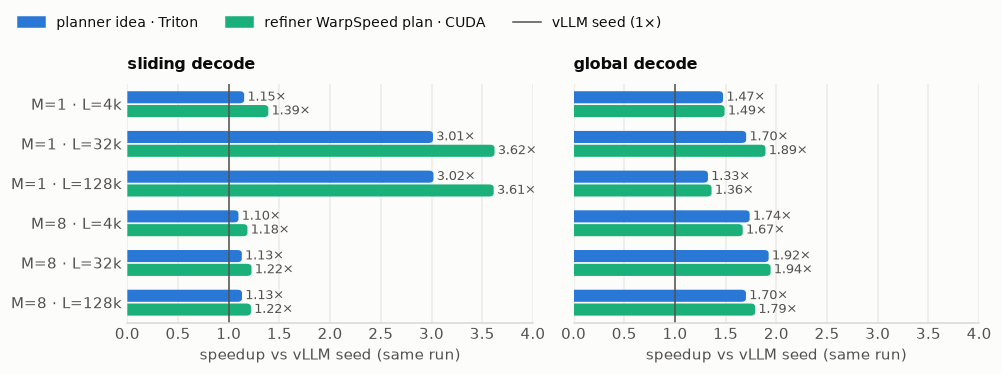

layer,M,L,design,origin,seed µs,design µs,speedup,first impl. speedup,launch,% SOL (K+V),rel L2 design,rel L2 seed
sliding,1,4096,window_trim,planner sliding_decode p1/p3,23.9,20.8,1.15×,0.67×,—,53,1.52e-03,—
sliding,1,4096,ws_decode_sliding,refiner sliding_decode p1: load squad 1 warp -> compute squad 3 warps; KV page ring 2 x 16 KB; segment_partial drained by the load squad,23.9,17.2,1.39×,—,S=8,64,1.52e-03,—
sliding,1,32768,window_trim,planner sliding_decode p1/p3,62.5,20.7,3.01×,1.73×,—,53,1.52e-03,—
sliding,1,32768,ws_decode_sliding,refiner sliding_decode p1: load squad 1 warp -> compute squad 3 warps; KV page ring 2 x 16 KB; segment_partial drained by the load squad,62.3,17.2,3.62×,—,S=8,64,1.52e-03,—
sliding,1,131072,window_trim,planner sliding_decode p1/p3,62.6,20.7,3.02×,1.72×,—,53,1.52e-03,—
sliding,1,131072,ws_decode_sliding,refiner sliding_decode p1: load squad 1 warp -> compute squad 3 warps; KV page ring 2 x 16 KB; segment_partial drained by the load squad,62.3,17.2,3.61×,—,S=8,64,1.52e-03,—
sliding,8,4096,window_trim,planner sliding_decode p1/p3,110.6,100.9,1.10×,0.93×,—,87,1.45e-03,—
sliding,8,4096,ws_decode_sliding,refiner sliding_decode p1: load squad 1 warp -> compute squad 3 warps; KV page ring 2 x 16 KB; segment_partial drained by the load squad,111.1,93.8,1.18×,—,S=1,94,1.45e-03,—
sliding,8,32768,window_trim,planner sliding_decode p1/p3,114.0,101.0,1.13×,0.96×,—,87,1.45e-03,—
sliding,8,32768,ws_decode_sliding,refiner sliding_decode p1: load squad 1 warp -> compute squad 3 warps; KV page ring 2 x 16 KB; segment_partial drained by the load squad,114.4,93.4,1.22×,—,S=1,94,1.45e-03,—


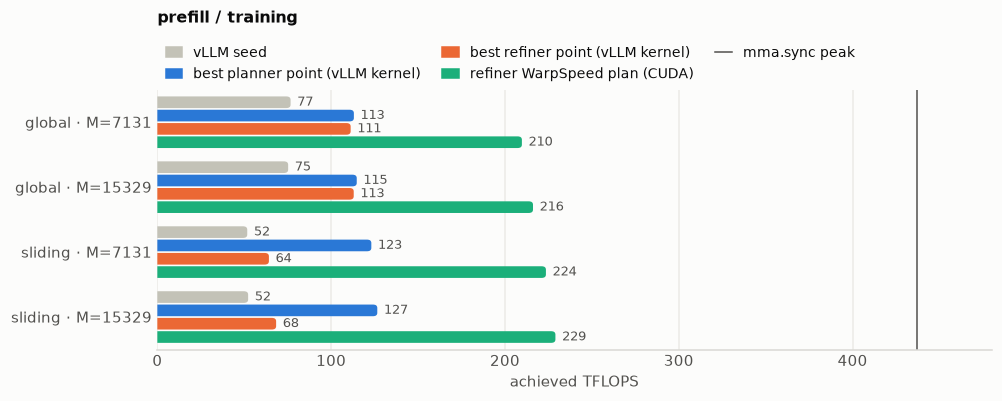

layer,M,design,origin,BLOCK_M,TILE,warps,stages,seed ms,design ms,speedup,TFLOPS,rel L2,error
sliding,7131,seed_tiled_64x32_w8_s2,planner sliding_prefill p0,64,32,8,2,4.294,1.804,2.38×,123,1.46e-03,
sliding,7131,seed_tiled_64x64_w16_s3,planner sliding_prefill p1,64,64,16,3,4.294,—,—,—,—,"OutOfResources: out of resource: shared memory, Required: 139776, Hardware limit: 101376. Reducing block sizes or `num_stages` may help."
sliding,7131,seed_tiled_32x32_w8_s2,planner sliding_prefill p2,32,32,8,2,4.294,2.477,1.73×,90,1.46e-03,
sliding,7131,seed_tiled_64x32_w8_s3,planner sliding_prefill p3,64,32,8,3,4.294,1.945,2.21×,114,1.46e-03,
sliding,15329,seed_tiled_64x32_w8_s2,planner sliding_prefill p0,64,32,8,2,9.519,3.929,2.42×,127,1.46e-03,
sliding,15329,seed_tiled_64x64_w16_s3,planner sliding_prefill p1,64,64,16,3,9.519,—,—,—,—,"OutOfResources: out of resource: shared memory, Required: 139776, Hardware limit: 101376. Reducing block sizes or `num_stages` may help."
sliding,15329,seed_tiled_32x32_w8_s2,planner sliding_prefill p2,32,32,8,2,9.519,5.469,1.74×,91,1.46e-03,
sliding,15329,seed_tiled_64x32_w8_s3,planner sliding_prefill p3,64,32,8,3,9.519,4.236,2.25×,117,1.46e-03,
global,7131,seed_tiled_32x32_w8_s3,planner global_prefill p0,32,32,8,3,21.741,14.740,1.48×,113,1.35e-03,
global,7131,seed_tiled_32x64_w8_s2,planner global_prefill p1,32,64,8,2,21.741,—,—,—,—,"OutOfResources: out of resource: shared memory, Required: 167936, Hardware limit: 101376. Reducing block sizes or `num_stages` may help."


In [14]:
des = [d["p"] for d in records(DENEB / "results.csv", "design_measurement")]
if not des: pending("implementation and measurement of the refined designs.")
else:
    alld = [d for d in des if d["phase"] == "decode" and "design_ms" in d]
    key = lambda d: (d["kind"], d["design"], d["B"], d["L"])
    final = {}
    for d in sorted(alld, key=lambda d: d.get("run", 1)):
        final[key(d)] = d
    first = {key(d): d for d in sorted(alld, key=lambda d: -d.get("run", 1))}
    dec = sorted(final.values(), key=lambda d: (d["kind"] != "sliding", d["B"], d["L"]))
    for d in dec:
        d["first_speedup"] = first[key(d)]["speedup"] if first[key(d)].get("run", 1) != d.get("run", 1) else None
    if dec:
        kinds = [k for k in ("sliding", "global") if any(d["kind"] == k for d in dec)]
        axs = fig_rows(6, 2, panels=len(kinds))
        for ax, k in zip(axs, kinds):
            shapes = sorted({(d["B"], d["L"]) for d in dec if d["kind"] == k})
            pick = lambda pre: [next((d["speedup"] for d in dec if d["kind"] == k and (d["B"], d["L"]) == x and d["design"].startswith(pre)), None) for x in shapes]
            hbars(ax, [f"M={b} · L={l // 1024}k" for b, l in shapes],
                  [("planner idea · Triton", pick("window_trim" if k == "sliding" else "v_only"), S1),
                   ("refiner WarpSpeed plan · CUDA", pick("ws_"), S3)],
                  label_fmt="{:.2f}×", xmax=4.0, ref=(1.0, "vLLM seed"), xlabel="speedup vs vLLM seed (same run)", legend=False)
            ax.set_title(f"{k} decode")
            if k != kinds[0]: ax.set_yticklabels([])
        fig = axs[0].figure
        fig.legend(handles=[mpl.patches.Patch(color=S1, label="planner idea · Triton"), mpl.patches.Patch(color=S3, label="refiner WarpSpeed plan · CUDA"),
                            mpl.lines.Line2D([], [], color=INK2, linewidth=1, label="vLLM seed (1×)")],
                   loc="upper left", bbox_to_anchor=(0.01, 1.0), ncol=3, frameon=False)
        plt.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()
        display(pd.DataFrame([{"layer": d["kind"], "M": d["B"], "L": d["L"], "design": d["design"], "origin": d["origin"],
                               "seed µs": 1e3 * d["seed_ms"], "design µs": 1e3 * d["design_ms"], "speedup": d["speedup"],
                               "first impl. speedup": d["first_speedup"],
                               "launch": (f"S={d['segments']}" + (f" T={d['tile']} st={d['stages']}" if "tile" in d else "")) if "segments" in d else "—",
                               "% SOL (K+V)": 100 * d["sol_ms"] / d["design_ms"], "rel L2 design": d["rel_l2"],
                               "rel L2 seed": (d.get("seed_check") or {}).get("rel_l2")}
                              for d in sorted(dec, key=lambda d: (d["kind"] != "sliding", d["B"], d["L"], d["design"]))]).style.format(
            {"seed µs": "{:.1f}", "design µs": "{:.1f}", "speedup": "{:.2f}×", "first impl. speedup": "{:.2f}×", "% SOL (K+V)": "{:.0f}",
             "rel L2 design": "{:.2e}", "rel L2 seed": "{:.2e}"}, na_rep="—").hide(axis="index"))
    pf = [d for d in des if d["phase"] == "prefill"]
    if pf:
        def best_of(src, ws_kernel=False):
            out = {}
            for d in pf:
                if "design_ms" in d and d["origin"].startswith(src) and d["design"].startswith("ws_") == ws_kernel:
                    k = (d["kind"], d["M"])
                    if k not in out or d["design_ms"] < out[k]["design_ms"]: out[k] = d
            return out
        ws = {(d["kind"], d["M"]): d for d in pf if d["design"].startswith("ws_") and "design_ms" in d}
        bp = best_of("planner")
        br = best_of("refiner")
        keys = sorted(set(bp) | set(br) | set(ws))
        anyrow = lambda x: bp.get(x) or br.get(x) or ws[x]
        series = [("vLLM seed", [anyrow(x)["flops"] / (anyrow(x)["seed_ms"] * 1e9) for x in keys], MUTED),
                  ("best planner point (vLLM kernel)", [bp[x]["tflops"] if x in bp else None for x in keys], S1)]
        if br: series.append(("best refiner point (vLLM kernel)", [br[x]["tflops"] if x in br else None for x in keys], S2))
        if ws: series.append(("refiner WarpSpeed plan (CUDA)", [ws[x]["tflops"] if x in ws else None for x in keys], S3))
        ax, = fig_rows(len(keys), len(series))
        hbars(ax, [f"{k} · M={m}" for k, m in keys], series, label_fmt="{:.0f}", xmax=480, ref=(437, "mma.sync peak"), xlabel="achieved TFLOPS")
        ax.set_title("prefill / training", pad=44); plt.tight_layout(); plt.show()
        display(pd.DataFrame([{"layer": d["kind"], "M": d["M"], "design": d["design"], "origin": d["origin"], "BLOCK_M": d["BLOCK_M"], "TILE": d["TILE"],
                               "warps": d["warps"], "stages": d["stages"], "seed ms": d["seed_ms"], "design ms": d.get("design_ms"),
                               "speedup": d.get("speedup"), "TFLOPS": d.get("tflops"), "rel L2": d.get("rel_l2"), "error": d.get("error", "")}
                              for d in pf]).style.format({"seed ms": "{:.3f}", "design ms": "{:.3f}", "speedup": "{:.2f}×", "TFLOPS": "{:.0f}",
                                                          "rel L2": "{:.2e}"}, na_rep="—").hide(axis="index"))

**2.9 End to end in vLLM 0.32 (decode).** Gemma 4 31B + `cake_scoped_c1` (rank-16 LoRA), one G4, greedy, B ≤ 8. `stock_compiled` = vLLM default (torch.compile + CUDA graphs); `stock` = eager modules + full decode graphs; `attn` = `stock` + WarpSpeed decode attention (`ws_decode_sliding`, `ws_decode_global` on the V half of vLLM's own cache, K rebuilt); `attn_gemv8` = `attn` + the user's `forge_gemv8` MLP chain for M ≤ 8. Step = (t₂₅₇ − t₁)/256, best of 3, prefix-cached random prompt; `concurrent` = most sequences the scheduler ran together (must equal B). 8 × 32k: `max_num_batched_tokens` 1,024 and `language_model_only` (vLLM admits each sliding-window request against window + 2 × chunk blocks), same for both modes.

B × L,stock_compiled tok/s,stock tok/s,attn tok/s,attn_gemv8 tok/s,attn_gemv8 vs stock_compiled,attn vs stock,gemv8 on top,all concurrent
1 × 556,52.2,50.4,50.5,55.2,1.06×,1.00×,1.09×,True
8 × 556,365.3,353.1,359.6,384.9,1.05×,1.02×,1.07×,True
"1 × 32,768",42.1,40.9,47.8,52.0,1.24×,1.17×,1.09×,True
"8 × 8,192",291.1,283.6,315.3,334.8,1.15×,1.11×,1.06×,True
"8 × 32,768",209.8,—,—,273.7,1.30×,—,—,True


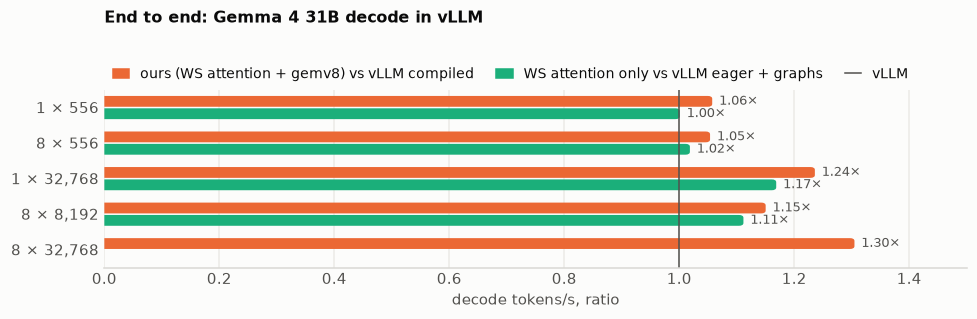

In [15]:
e2e = [e["p"] for e in records(DENEB / "results.csv", "e2e_measurement") if e["p"]["kind"] == "decode"]
if not e2e: pending("end-to-end runs.")
else:
    tps = {(r["mode"], r["B"], r["L"]): r["tokens_per_s"] for r in e2e}
    conc = {(r["mode"], r["B"], r["L"]): r.get("concurrent") for r in e2e}
    shapes = sorted({(r["B"], r["L"]) for r in e2e}, key=lambda x: (x[1] * x[0], x[0]))
    modes = ("stock_compiled", "stock", "attn", "attn_gemv8")
    ratio = lambda m, ref, s: tps[(m, *s)] / tps[(ref, *s)] if (m, *s) in tps and (ref, *s) in tps else None
    df = pd.DataFrame([{"B × L": f"{B} × {L:,}", **{f"{m} tok/s": tps.get((m, B, L)) for m in modes},
                        "attn_gemv8 vs stock_compiled": ratio("attn_gemv8", "stock_compiled", (B, L)),
                        "attn vs stock": ratio("attn", "stock", (B, L)), "gemv8 on top": ratio("attn_gemv8", "attn", (B, L)),
                        "all concurrent": all(conc[(m, B, L)] in (None, B) for m in modes if (m, B, L) in conc)} for B, L in shapes])
    display(df.style.format({**{f"{m} tok/s": "{:.1f}" for m in modes}, "attn_gemv8 vs stock_compiled": "{:.2f}×",
                             "attn vs stock": "{:.2f}×", "gemv8 on top": "{:.2f}×"}, na_rep="—").hide(axis="index"))
    ax, = fig_rows(len(shapes), 2)
    hbars(ax, list(df["B × L"]), [("ours (WS attention + gemv8) vs vLLM compiled", list(df["attn_gemv8 vs stock_compiled"]), S2),
                                  ("WS attention only vs vLLM eager + graphs", list(df["attn vs stock"]), S3)],
          label_fmt="{:.2f}×", xmax=1.5, ref=(1.0, "vLLM"), xlabel="decode tokens/s, ratio")
    ax.set_title("End to end: Gemma 4 31B decode in vLLM", pad=44); plt.tight_layout(); plt.show()